# Browser memory and precision

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/20-performance.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/20-performance.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `60fd0643c1389cd0ec66a145faf41ee3f39739749ad32451b24bb91fed667d7b`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Browser memory and precision

**Lesson 20 · Original synthetic data · Independent educational project**

## Objectives

Estimate array costs; quantify float32 approximation error.

[Previous](19-dashboard.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/20-performance.ipynb) · [Next](21-reproducibility.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=20-performance.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

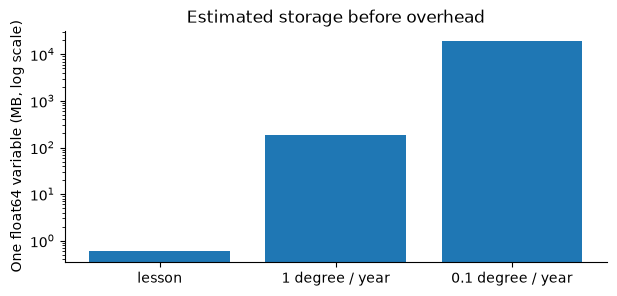

Lesson array 0.59 MB; float32 error 1.53e-05 K


In [2]:
cube = lab.synthetic_cube(); original = cube["temperature"]
compact = original.astype(np.float32)
error = np.max(np.abs(original - compact.astype(np.float64)))
assert compact.nbytes * 2 == original.nbytes
assert error < 5e-5
sizes = np.array([25*49*60, 180*360*365, 1800*3600*365], dtype=np.int64)
megabytes = sizes*8/1e6
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(["lesson", "1 degree / year", "0.1 degree / year"], megabytes)
ax.set_yscale("log")
ax.set(ylabel="One float64 variable (MB, log scale)", title="Estimated storage before overhead")
plt.show()
print(f"Lesson array {original.nbytes/1e6:.2f} MB; float32 error {error:.2e} K")

## Exercise

Add ten variables and an ensemble of twenty members to the estimates. Propose a subset that fits a 100 MB working budget.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Array storage is only part of memory use: temporary arrays, decompression, plotting and the browser add overhead. A lightweight lesson is not evidence that a full-resolution twin fits in a browser.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://numpy.org/doc/stable/reference/arrays.ndarray.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).